In [162]:
# ARCH & GARCH Volatility Forecasting for 5 Assets

# Install required packages
!pip install yfinance arch

# Import libraries
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np




In [163]:
# prompt: ignore warnings

import warnings
warnings.filterwarnings('ignore')


In [164]:


# Step 1: Select 5 assets (coins, forex pairs, or stocks)
assets = ['BTC-USD', 'ETH-USD','XRP-USD', 'EURUSD=X', 'GC=F']  # BTC, ETH, Forex, Stocks
start_date = '2024-01-01'
end_date = '2025-04-08'

# Step 2: Download daily close prices and calculate log returns
data = yf.download(assets, start=start_date, end=end_date, interval = '1h')['Close']
df = data.pct_change().dropna()


[*********************100%***********************]  5 of 5 completed


In [165]:
split_idx = int(len(df) * 0.8)

train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()

print("Train size:", len(train))
print("Test size:", len(test))

Train size: 8878
Test size: 2220


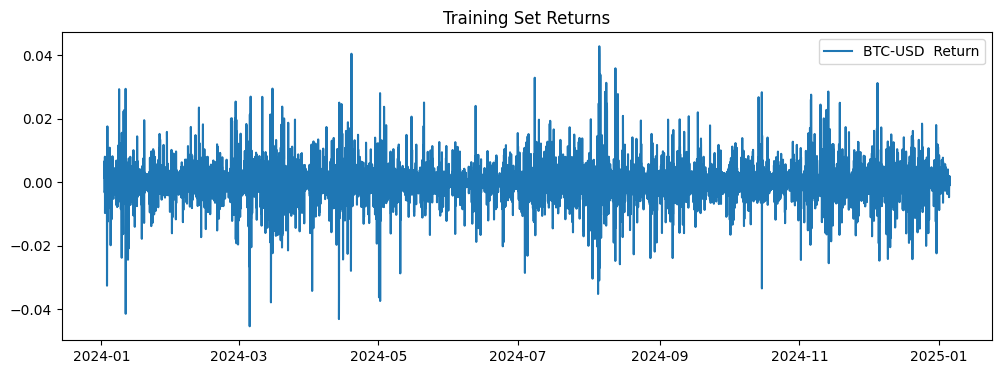

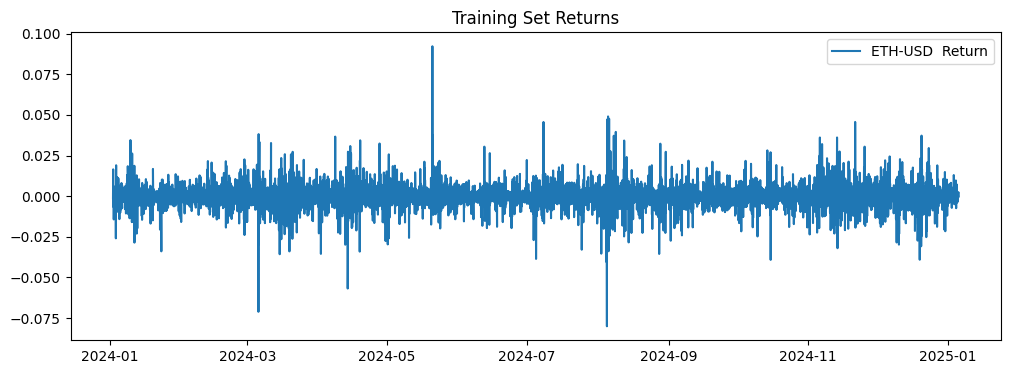

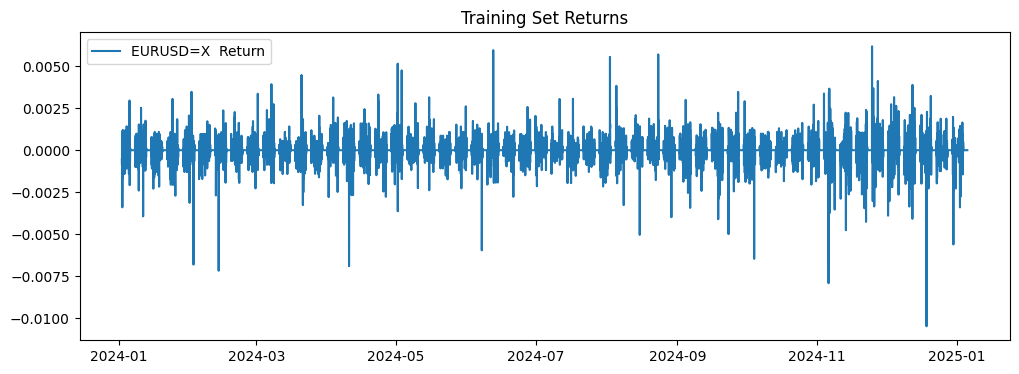

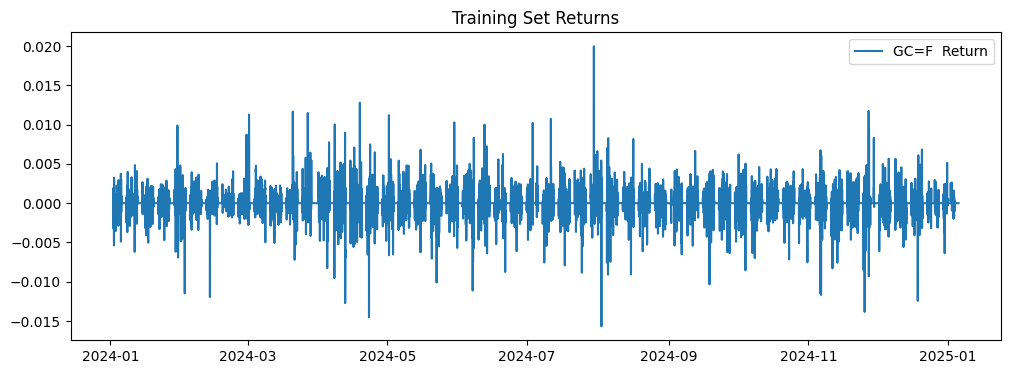

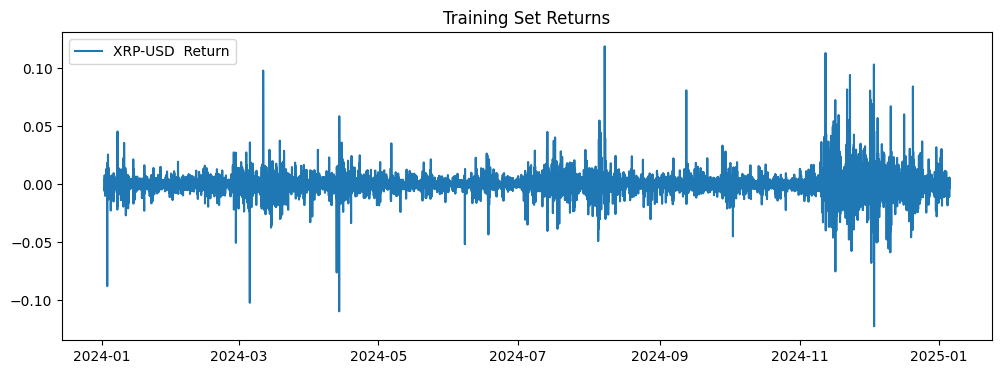

In [166]:
for ticker in train:
  plt.figure(figsize=(12, 4))
  plt.plot(train[f'{ticker}'], label=f'{ticker}  Return')
  plt.title('Training Set Returns')
  plt.legend()
  plt.show()

In [169]:
ticker = 'BTC-USD'
history = train[f'{ticker}'].dropna().to_list()
pred_arches = []
pred_garches = []


for t in range(len(test)):
  arch_mod = arch_model(history, vol='ARCH', p=1, rescale = True)
  arch_res = arch_mod.fit(disp='off')
  garch_mod = arch_model(history , vol='GARCH', p=1, q=1, rescale = True)
  garch_res = garch_mod.fit(disp='off')
  pred_arch = arch_res.forecast(horizon=1).variance.iloc[-1]
  pred_garch = garch_res.forecast(horizon=1).variance.iloc[-1]
  pred_arches.append(pred_arch)
  pred_garches.append(pred_garch)
  history.append(test[f'{ticker}'].iloc[t])

actual_vol = test[f'{ticker}']**2
MSE_arch = mean_squared_error(actual_vol, pred_arches)
RMSE_arch = np.sqrt(MSE_arch)
MAE_arch = mean_absolute_error(actual_vol, pred_arches)
print(f"ARCH MSE: {ticker}", MSE_arch)
print(f"ARCH RMSE: {ticker}", RMSE_arch)
print(f"ARCH MAE: {ticker}" , MAE_arch)

MSE_garch = mean_squared_error(actual_vol, pred_garches)
RMSE_garch = np.sqrt(MSE_garch)
MAE_garch = mean_absolute_error(actual_vol, pred_garches)
print(f"GARCH MSE: {ticker}", MSE_garch)
print(f"GARCH RMSE: {ticker}", RMSE_garch)
print(f"GARCH MAE: {ticker}", MAE_garch)

print (f'STD: {ticker}', np.std(actual_vol))


ARCH MSE: BTC-USD 0.391448665974346
ARCH RMSE: BTC-USD 0.6256585857912812
ARCH MAE: BTC-USD 0.3590952028726138
GARCH MSE: BTC-USD 0.4714452915714951
GARCH RMSE: BTC-USD 0.6866187381447546
GARCH MAE: BTC-USD 0.4094343834232421
STD: BTC-USD 0.00012821059786092783


In [168]:
for ticker in train:
  history = train[f'{ticker}'].dropna().to_list()
  pred_arches = []
  pred_garches = []


  for t in range(len(test)):
    arch_mod = arch_model(history, vol='ARCH', p=1, rescale = False)
    arch_res = arch_mod.fit(disp='off')
    garch_mod = arch_model(history , vol='GARCH', p=1, q=1, rescale = False)
    garch_res = garch_mod.fit(disp='off')
    pred_arch = arch_res.forecast(horizon=1).variance.iloc[-1]
    pred_garch = garch_res.forecast(horizon=1).variance.iloc[-1]
    pred_arches.append(pred_arch)
    pred_garches.append(pred_garch)
    history.append(test[f'{ticker}'].iloc[t])

  actual_vol = test[f'{ticker}']**2
  MSE_arch = mean_squared_error(actual_vol, pred_arches)
  RMSE_arch = np.sqrt(MSE_arch)
  MAE_arch = mean_absolute_error(actual_vol, pred_arches)
  print(f"ARCH MSE: {ticker}", MSE_arch)
  print(f"ARCH RMSE: {ticker}", RMSE_arch)
  print(f"ARCH MAE: {ticker}" , MAE_arch)

  MSE_garch = mean_squared_error(actual_vol, pred_garches)
  RMSE_garch = np.sqrt(MSE_garch)
  MAE_garch = mean_absolute_error(actual_vol, pred_garches)
  print(f"GARCH MSE: {ticker}", MSE_garch)
  print(f"GARCH RMSE: {ticker}", RMSE_garch)
  print(f"GARCH MAE: {ticker}", MAE_garch)

  print (f'STD: {ticker}', np.std(actual_vol))

/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/uni

ARCH MSE: BTC-USD 1.58712855495714e-08
ARCH RMSE: BTC-USD 0.00012598129047430574
ARCH MAE: BTC-USD 4.328618353186104e-05
GARCH MSE: BTC-USD 88410.72753932302
GARCH RMSE: BTC-USD 297.33941470871804
GARCH MAE: BTC-USD 9.788511341298095
STD: BTC-USD 0.00012821059786092783


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.war

ARCH MSE: ETH-USD 1.972299674209107e-07
ARCH RMSE: ETH-USD 0.0004441058065606784
ARCH MAE: ETH-USD 9.508503249634744e-05
GARCH MSE: ETH-USD 0.6322620842843907
GARCH RMSE: ETH-USD 0.795149095632002
GARCH MAE: ETH-USD 0.06484219938368087
STD: ETH-USD 0.00042517739854226055


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.war

ARCH MSE: EURUSD=X 0.00012834829137434834
ARCH RMSE: EURUSD=X 0.011329090491930423
ARCH MAE: EURUSD=X 0.00024164548569779223
GARCH MSE: EURUSD=X 1240.1445789464087
GARCH RMSE: EURUSD=X 35.21568654657195
GARCH MAE: EURUSD=X 0.9831857958453613
STD: EURUSD=X 4.753343023385068e-06


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.war

ARCH MSE: GC=F 1.736648574410423e-06
ARCH RMSE: GC=F 0.0013178196289365335
ARCH MAE: GC=F 5.16560507641901e-05
GARCH MSE: GC=F 0.18374256118965082
GARCH RMSE: GC=F 0.42865202809464326
GARCH MAE: GC=F 0.01968819520058216
STD: GC=F 1.4011373581434171e-05


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.war

ARCH MSE: XRP-USD 7.35337231797539e-07
ARCH RMSE: XRP-USD 0.0008575180649977813
ARCH MAE: XRP-USD 0.0001823500434898988
GARCH MSE: XRP-USD 0.03649296823864256
GARCH RMSE: XRP-USD 0.1910313278984433
GARCH MAE: XRP-USD 0.005964825159973149
STD: XRP-USD 0.0008426496560061452
